# Лабораторная работа 5. Сервис синтеза

Юдин Артём М4221

**Цель работы:** собрать нормализатор, предиктор пауз, транскриптор и акустическую модель в один тракт: на входе текст, на выходе звук.

Ноутбук считает копи-синтез через HiFi-GAN, синтезирует 10 фраз из `data/evaluation_text.csv` и печатает время по этапам и RTF. Запускать его нужно там, где уже лежат веса FastSpeech2 и корпус RUSLAN: чекпоинты в git не входят. Каталог запуска - `labs/lab4_acoustic/runs/baseline/baseline_g2p`. Это модель, обученная на фонемах того же G2P. В лабораторной работе №4 её средний MCD был 27,2 дБ против 62,5 дБ у постоянного мел-спектра.

`speechbrain` и `num2words` добавлены в `pyproject.toml`. Ставить их нужно в уже собранное окружение лабораторной работы №4, чтобы не подменять torch 2.5.1+cu121 и форк Coqui. Полный `uv sync` по новому lock-файлу разрешает более свежий torch, который speechbrain тянет за собой.


# 1. Схема тракта и стыковка работ №1–4

```
текст
  → normalize        TextNormalizer, лабораторная работа №1
  → tokenize         токены label_raw: слово и пунктуация до следующего слова
  → insert_pauses    PausePredictor.predict_durations, вставляет <SIL>
  → to_phones        G2P, <SIL> проходит без изменений
  → куски примерно по 24 токена
  → mel              FastSpeech2, baseline_g2p
  → vocode           HiFi-GAN LibriTTS 22 050 Гц
звук
```

Публичные методы работ №1–3 не менялись. Тракт только подаёт им те формы, которые они уже описывают.

- Нормализатор сам приводит текст к NFC.
- Токен для предиктора пауз - это слово плюс пунктуация до следующего слова. Знаки до первого слова остаются на первом токене. Так устроен столбец `label_raw`.
- `G2P.transcribe` сам пропускает `<SIL>` и ищет слово в нижнем регистре без знака ударения и без пунктуации. Отдельно приводить ключ словаря в тракте не нужно.
- Незнакомое слово идёт в буквенные правила G2P. Телефоны вне `common/phones_mfa.txt` отбрасываются.
- Модели загружаются один раз в `TTSPipeline.__init__`. Предиктор пауз при этом заново учится на всей таблице пауз, поэтому первая ячейка с инициализацией долгая.

Длинная фраза режется уже в тракте, до FastSpeech2. Разрез ищет `<SIL>` или токен, который кончается знаком препинания, и оставляет паузу при предыдущем куске. Кусок не длиннее 25 токенов: лишний токен - это `<SIL>` сразу после разреза.


In [1]:
from pathlib import Path
import sys

import torch

HERE = Path.cwd().resolve()
ROOT = next(
    path for path in (HERE, *HERE.parents)
    if (path / "labs" / "lab5_service" / "tts_pipeline.py").is_file()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from labs.lab5_service.tts_pipeline import (  # noqa: E402
    SAMPLE_RATE,
    TTSPipeline,
    chunk_tokens,
    tokenize_text,
)

LAB5 = ROOT / "labs" / "lab5_service"
RUN_DIR = ROOT / "labs" / "lab4_acoustic" / "runs" / "baseline" / "baseline_g2p"
AUDIO_DIR = LAB5 / "audio"
AUDIO_DIR.mkdir(parents=True, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"device {device}, torch {torch.__version__}")
print(f"run {RUN_DIR}")
pipeline = TTSPipeline(RUN_DIR, device=device)


device cuda, torch 2.5.1+cu121
run /home/jovyan/iudin/tts_labs_itmo/labs/lab4_acoustic/runs/baseline/baseline_g2p


/home/jovyan/iudin/tts_labs_itmo/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/jovyan/iudin/tts_labs_itmo/.venv/lib/python3.10/site-packages/coqpit/coqpit.py:875: UserWarning: Type mismatch in Fastspeech2Config
Failed to deserialize field: characters (<class 'TTS.tts.configs.shared_configs.CharactersConfig'>) = {'characters_class': 'TTS.tts.utils.text.characters.MulticharPhonemes', 'vocab_dict': None, 'pad': '<PAD>', 'eos': '<EOS>', 'bos': '<BOS>', 'blank': '<BLNK>', 'characters': ['<SIL>', 'a', 'b', 'bʲ', 'c', 'dʐ', 'dʲ', 'd̪', 'd̪z̪', 'e', 'f', 'fʲ', 'i', 'j', 'k', 'm', 'mʲ', 'n̪', 'o', 'p', 'pʲ', 'r', 'rʲ', 'sʲ', 's̪', 'tɕ', 'tʂ', 'tʲ', 't̪', 't̪s̪', 'u', 'v', 'vʲ', 'x', 'zʲ', 'z̪', 'æ', 'ç', 'ɐ', 'ɕ', 'ə', 'ɛ', 'ɟ', 'ɡ', 'ɣ', 'ɨ', 'ɪ', 'ɫ', 'ɲ', 'ɵ', 'ʂ', 'ʉ', 'ʊ', 'ʎ', 'ʐ', 'ʑ'], 'punctuations': '', 'phonemes': None, 'is_unique': False, 'is_sorted': True}
Value `['<SIL>', 'a', 'b', 'bʲ', 'c', 'dʐ', 'dʲ', 'd̪', 'd̪z̪', 'e', 'f', 'fʲ', 'i', 'j', 'k', 'm', 'mʲ', 'n̪', 'o', 'p', 'pʲ', 'r', 'rʲ', 'sʲ', 's̪', 'tɕ', 'tʂ', 'tʲ', 't̪', 't̪s̪', 'u', 'v', 'vʲ', '

/home/jovyan/iudin/tts_labs_itmo/.venv/lib/python3.10/site-packages/torch/nn/utils/weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
/home/jovyan/iudin/tts_labs_itmo/.venv/lib/python3.10/site-packages/speechbrain/utils/checkpoints.py:200: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.seri

Fitting hist_gradient_boosting


Validation F1: 0.7517626487675559
Pause threshold 0.370 on 175050 train tokens


# 2. Вокодер

HiFi-GAN взят готовый: `speechbrain/tts-hifigan-libritts-22050Hz`. Он обучен не на настройках Coqui по умолчанию. Пять отличий, из-за которых копи-синтез либо звучит как запись, либо нет:

- `spec_gain` — 1, а не 20. Иначе мел в двадцать раз крупнее, чем ждёт вокодер.
- `log_func` — `np.log`, а не `np.log10`. Вокодер учился на натуральном логарифме.
- `signal_norm` — выключен. Лишняя min-max нормализация сдвигает диапазон.
- `do_trim_silence` — выключен. Обрезка тишины меняет число кадров.
- `mel_fmax` — 8000, а не `None`. Так указано в карточке модели.

Запись RUSLAN превращается в мел и сразу подаётся в HiFi-GAN. Рядом сохраняется Гриффин-Лим по тому же мелу: это потолок, который был слышен в работе №4. У настоящей записи RUSLAN мел лежит примерно в диапазоне [-10,2; 0,5].

На слух `copysynth_hifigan.wav` близко к `natural.wav`, `copysynth_griffinlim.wav` заметно более звонкий и «металлический».


In [2]:
import torch
from IPython.display import Audio, Markdown, display
from TTS.config.shared_configs import BaseAudioConfig
from TTS.utils.audio import AudioProcessor

audio_config = BaseAudioConfig(
    sample_rate=22050,
    fft_size=1024,
    win_length=1024,
    hop_length=256,
    num_mels=80,
    mel_fmin=0.0,
    mel_fmax=8000.0,
    spec_gain=1.0,
    log_func="np.log",
    signal_norm=False,
    do_trim_silence=False,
    preemphasis=0.0,
    ref_level_db=20,
    trim_db=60.0,
)
ap = AudioProcessor.init_from_config(audio_config)

run_audio = pipeline.config.audio
for name, expected in (
    ("mel_fmax", 8000.0),
    ("spec_gain", 1.0),
    ("log_func", "np.log"),
    ("signal_norm", False),
    ("do_trim_silence", False),
):
    actual = getattr(run_audio, name)
    print(f"{name}: run={actual!r} vocoder={expected!r} match={actual == expected}")


def find_wav(root: Path) -> Path:
    directories = (
        root / "data" / "RUSLAN" / "RUSLAN",
        root / "data" / "ruslan_dataset" / "RUSLAN",
    )
    for directory in directories:
        preferred = directory / "000000_RUSLAN.wav"
        if preferred.is_file():
            return preferred
        if directory.is_dir():
            found = sorted(directory.glob("*.wav"))
            if found:
                return found[0]
    raise FileNotFoundError(
        "Нет wav в data/RUSLAN/RUSLAN или data/ruslan_dataset/RUSLAN"
    )


wav_path = find_wav(ROOT)
print(f"source {wav_path}")
natural = ap.load_wav(str(wav_path))
mel = ap.melspectrogram(natural)
print(f"mel {tuple(mel.shape)}, range [{mel.min():.2f}, {mel.max():.2f}]")
if mel.min() < -12 or mel.max() > 2:
    print("Диапазон далеко от [-10.2, 0.5]: конфигурация мела не совпадает с вокодером.")

mel_tensor = torch.tensor(mel, device=pipeline.device)
with torch.no_grad():
    hifigan = pipeline.vocoder.decode_batch(mel_tensor).squeeze().cpu().numpy()
griffin = ap.inv_melspectrogram(mel)

copies = {
    "natural.wav": natural,
    "copysynth_hifigan.wav": hifigan,
    "copysynth_griffinlim.wav": griffin,
}
for name, signal in copies.items():
    path = AUDIO_DIR / name
    ap.save_wav(signal, str(path), sr=22050)
    display(Markdown(f"**{name}**"))
    display(Audio(signal, rate=SAMPLE_RATE))


mel_fmax: run=8000.0 vocoder=8000.0 match=True
spec_gain: run=1 vocoder=1.0 match=True
log_func: run='np.log' vocoder='np.log' match=True
signal_norm: run=False vocoder=False match=True
do_trim_silence: run=False vocoder=False match=True
source /home/jovyan/iudin/tts_labs_itmo/data/RUSLAN/RUSLAN/000000_RUSLAN.wav
mel (80, 194), range [-10.24, 0.50]


**natural.wav**

**copysynth_hifigan.wav**

**copysynth_griffinlim.wav**

# 3. Десять фраз и RTF

Фразы берутся из `data/evaluation_text.csv` как есть.

Первый вызов после загрузки всё ещё может быть дороже следующих: прогрев CUDA попадает в первую фразу.


In [3]:
import csv

import pandas as pd
from IPython.display import Audio, Markdown, display

eval_path = LAB5 / "data" / "evaluation_text.csv"
rows = list(csv.DictReader(eval_path.open(encoding="utf-8"), delimiter="|"))
records = []
for row in rows:
    utterance_id = row["id"]
    text = row["text"]
    normalized = pipeline.normalize(text)
    tokens = tokenize_text(normalized)
    groups = chunk_tokens(tokens)
    wav, timings = pipeline(text)
    pipeline.save(wav, AUDIO_DIR / f"{utterance_id}.wav")
    display(Markdown(f"### {utterance_id}"))
    display(Markdown(text))
    print(f"токенов {len(tokens)}, кусков {len(groups)}, нормализовано: {normalized}")
    if len(wav):
        display(Audio(wav, rate=SAMPLE_RATE))
    else:
        print("пустая волна")
    print(timings.report())
    record = {
        "id": utterance_id,
        "chars": len(text),
        "tokens": len(tokens),
        "chunks": len(groups),
        "audio_s": timings.audio_seconds,
        "total_s": timings.total,
        "rtf": timings.rtf,
    }
    record.update({f"{name}_s": value for name, value in timings.stages.items()})
    records.append(record)

TIMINGS = pd.DataFrame(records)


### eval_01

Мы всем отрядом съели все, что было во всем лагере и все остались довольны.

токенов 14, кусков 1, нормализовано: Мы всем отрядом съели все, что было во всем лагере и все остались довольны.


  normalize           0.0 ms   0.0%
  tokenize            0.0 ms   0.0%
  pauses              5.9 ms   1.9%
  g2p                 0.1 ms   0.0%
  acoustic          272.7 ms  86.1%
  vocoder            38.1 ms  12.0%
  total             316.8 ms for 4.48 s of audio  ->  RTF 0.071


### eval_02

А он что? Да ты что! Вот оно что.

... (30 outputs left out)

### eval_10

‹‹Записываю витал-икону+наши хромосомы из выделений в присос =кровь хромосомы::горизонт жидкостей тела=убить как собаку, разложенную до голого гена =ТВ/спазм//

токенов 25, кусков 2, нормализовано: Записываю витал-икону плюс наши хромосомы из выделений в присос равно кровь хромосомы:горизонт жидкостей тела равно убить как собаку, разложенную до голого гена равно ТВспазм


  normalize           0.1 ms   0.1%
  tokenize            0.0 ms   0.0%
  pauses              6.6 ms   6.1%
  g2p                 0.3 ms   0.3%
  acoustic           28.3 ms  26.1%
  vocoder            73.1 ms  67.4%
  total             108.4 ms for 11.88 s of audio  ->  RTF 0.009


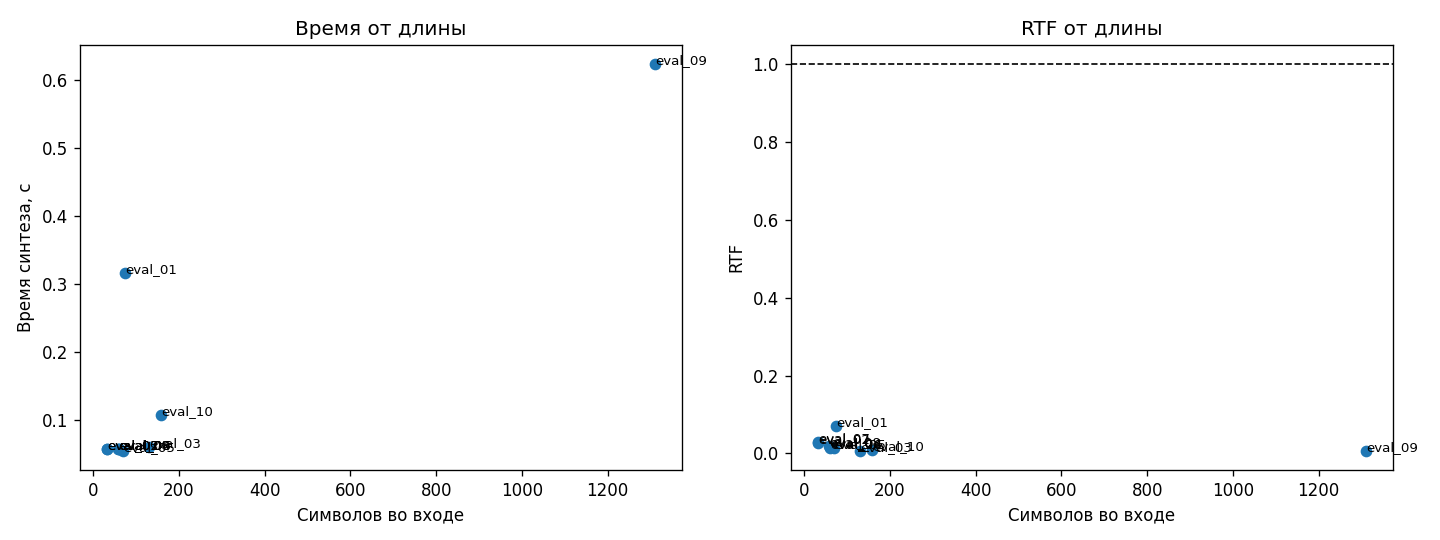

,id,chars,tokens,chunks,audio_s,total_s,rtf,normalize_s,tokenize_s,pauses_s,g2p_s,acoustic_s,vocoder_s
0,eval_01,75,14,1,4.481,0.317,0.071,0.0,0.0,0.006,0.000,0.273,0.038
1,eval_02,33,9,1,2.206,0.057,0.026,0.0,0.0,0.006,0.000,0.014,0.037
2,eval_03,130,13,1,8.998,0.061,0.007,0.0,0.0,0.007,0.000,0.015,0.039
3,eval_04,60,7,1,3.611,0.057,0.016,0.0,0.0,0.006,0.000,0.015,0.036
4,eval_05,69,10,1,4.145,0.055,0.013,0.0,0.0,0.006,0.000,0.013,0.036
5,eval_06,61,10,1,3.866,0.057,0.015,0.0,0.0,0.006,0.000,0.014,0.037
6,eval_07,32,6,1,1.939,0.057,0.029,0.0,0.0,0.005,0.000,0.014,0.038
7,eval_08,58,9,1,3.019,0.058,0.019,0.0,0.0,0.005,0.000,0.015,0.038
8,eval_09,1310,191,11,84.881,0.624,0.007,0.0,0.0,0.013,0.002,0.163,0.445
9,eval_10,159,25,2,11.877,0.108,0.009,0.0,0.0,0.007,0.000,0.028,0.073


In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(TIMINGS["chars"], TIMINGS["total_s"])
for _, row in TIMINGS.iterrows():
    axes[0].annotate(row["id"], (row["chars"], row["total_s"]), fontsize=8)
axes[0].set_xlabel("Символов во входе")
axes[0].set_ylabel("Время синтеза, с")
axes[0].set_title("Время от длины")

axes[1].scatter(TIMINGS["chars"], TIMINGS["rtf"])
axes[1].axhline(1.0, color="black", linestyle="--", linewidth=1)
for _, row in TIMINGS.iterrows():
    axes[1].annotate(row["id"], (row["chars"], row["rtf"]), fontsize=8)
axes[1].set_xlabel("Символов во входе")
axes[1].set_ylabel("RTF")
axes[1].set_title("RTF от длины")
plt.tight_layout()
plt.show()

TIMINGS.round(3)


# 4. Что получается на тестовых фразах

**eval_01.** Обычное предложение, 14 токенов, один кусок. Запятая висит на токене `все,`, точка на последнем слове, так что предиктор пауз их видит. Это самый спокойный пример: бытовая лексика.

**eval_02.** Девять токенов и три короткие реплики: `что?`, `что!`, `что.`. Восклицание и вопрос не отделены от слова, предиктор получает их как класс пунктуации. Фраза короткая, 22 фонемы. Интонации не передаются

**eval_03.** Тринадцать токенов и 112 фонем: имена науатль не из словаря. `шиупоуалли` читается буквенными правилами (`ʂ ɨ ʊ p ə ʊ a ʎ ɪ`), `Тлакашипеуалицтли` — тоже. `Шипе-Тотека` остаётся одним токеном из-за дефиса. Ударение ставит предиктор по хвосту слова, а не по языку-источнику. Ждать правильного науатля не стоит. На слух шипящие с металлическим отзвуком модели звучат нечленораздельно.

**eval_04.** Ошибка в ударении и в мягкости.

**eval_05.** `передохнут` в словаре нет. Оба вхождения, «тараканы передохнут» и «люди передохнут», получают одну и ту же цепочку `pʲ ɪ rʲ ɪ d̪ ɐ x n̪ u t̪`. Омограф «умрут» / «отдохнут» тракт не различает. Двойной дефис в `люди --` приклеен к слову и не является тире из разметки пауз, поэтому на этом месте предиктор легко не поставит `<SIL>`, хотя по смыслу здесь граница.

**eval_06.** Скороговорка, 10 токенов. `тупогуб` в словаре нет и читается правилами. Здесь проверяется, не слипаются ли похожие слоги. Текст не упрощался.

**eval_07.** `зальцбург` - OOV, правила дают `z̪ ɐ ʎ t̪s̪ b u r k`. Запятая после `Ах` и восклицание на `бы!` до предиктора доходят.

**eval_08.** `fabric` и `details` дают пустой список фонем. Слова из звука исчезают, русская рамка остаётся: «смотря какой, смотря сколько в этом пиджаке». В первой работе мы решили отбросить иностранные слова, поскольку их было мало. Решается переписыванием слов кириллицей. 

**eval_09.** 191 токен и 11 кусков. Куски режутся по пунктуации, склейка — это конкатенация волн, без дополнительной паузы на шве. Швы отчётливо слышны. `1800-х` раскрывается в `одна тысяча восемьсот-х`: количественное числительное, суффикс `-х` остаётся. Однако на слух воспринимается правильно.

**eval_10.** Скобки и звёздочки нормализатор выкидывает, `+` становится «плюс», `=` становится «равно». Слеш он тоже выкидывает, поэтому `ТВ/спазм` склеивается в `ТВспазм`. Но несмотря на такую нормализацию текста - слово слышится как просто `спазм`. Двоеточие остаётся на токене. На выходе 25 токенов, 2 куска и 147 фонем.

Общее ограничение акустической модели то же, что в работе №4. Голос роботизированный, слова при удачном ударении различимы. HiFi-GAN убирает металлический призвук Гриффина-Лима, но не делает из baseline_g2p другого диктора.



# 5. Входы, которые обработать нельзя

Пустая строка, строка из пробелов и строка без единого слова (`???`) не роняют скрипт. Тракт возвращает волну нулевой длины. Латинское слово без русской опоры (`fabric`) токенизируется, но фонем не даёт, и результат тоже пустой.

Смешанный вход вроде `eval_08` и `eval_10` - другой случай. Он обрабатывается частично. Нечитаемые куски пропадают, остальное произносится.


In [5]:
for sample in ("", "   ", "???", "fabric"):
    wav, timings = pipeline(sample)
    print(repr(sample), "samples", len(wav), "seconds", round(timings.audio_seconds, 3))
    print(timings.report() or "  этапов нет")


'' samples 0 seconds 0.0
  total               0.0 ms for 0.00 s of audio  ->  RTF inf
'   ' samples 0 seconds 0.0
  total               0.0 ms for 0.00 s of audio  ->  RTF inf
'???' samples 0 seconds 0.0
  normalize           0.0 ms  85.1%
  tokenize            0.0 ms  13.5%
  pauses              0.0 ms   1.4%
  total               0.0 ms for 0.00 s of audio  ->  RTF inf
'fabric' samples 0 seconds 0.0
  normalize           0.0 ms   0.3%
  tokenize            0.0 ms   0.1%
  pauses              5.4 ms  99.3%
  g2p                 0.0 ms   0.4%
  total               5.5 ms for 0.00 s of audio  ->  RTF inf


## Вывод

Модель справляется со сложной озвучкой, но с вышеописанными огрехами:
- Английские слова мы выбрасываем - исправляется умным парсером, который переписывает слова на кириллицу.
- Ударения не поддерживаются - как говорилось в первой работе, для этого далается специальной обучение с символом для обозначения ударений.
- Новый вокодер не делает из модели внезамно хорошей. Значит проблема лежит в генерации мелов, пути для решения были описаны в 4 работе.

Также важное уточнение - в первой работе была ошибка с num2words, которая осталась незамеченной до этой работы. Сейчас проблема решена и числа в eval_009 озвучиваются нормально.